In [9]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()
SHOTS = 100

## Predictions

**Part A – Correlated outcomes**

I predict that the measurement outcomes `00` and `11` will dominate, with approximately 50% probability each. The two qubits should produce the same measurement result.

**Part B – Opposite outcomes**

I predict that the measurement outcomes `01` and `10` will dominate, with approximately 50% probability each. The two qubits should produce opposite measurement results.

In the ideal simulator, only two of the four possible outcomes should appear in each circuit. The other outcomes have zero probability because of the quantum states created by the gates. Actual hardware may show other outcomes due to noise.

In [10]:
# Part A: Correlated outcomes
qc_a = QuantumCircuit(2, 2)

qc_a.h(0)
qc_a.cx(0, 1)

qc_a.measure(0, 0)
qc_a.measure(1, 1)


# Part B: Opposite outcomes
qc_b = QuantumCircuit(2, 2)

qc_b.h(0)
qc_b.cx(0, 1)
qc_b.x(1)  # One additional gate switches the correlation

qc_b.measure(0, 0)
qc_b.measure(1, 1)

Part A: Correlated Outcomes


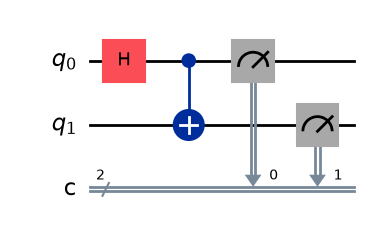

Part B: Opposite Outcomes


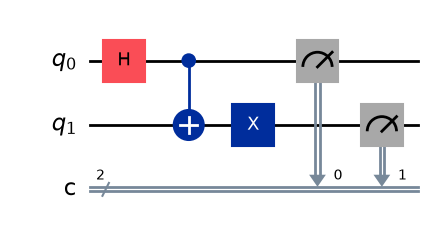

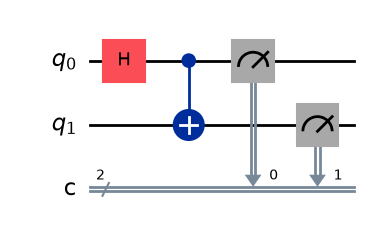

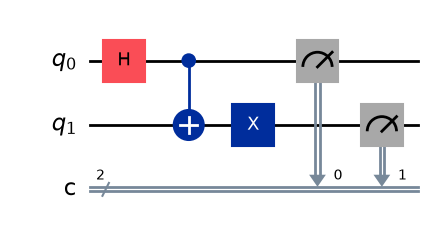

In [11]:
print("Part A: Correlated Outcomes")
display(qc_a.draw("mpl"))

print("Part B: Opposite Outcomes")
display(qc_b.draw("mpl"))

In [12]:
# Execute Part A
result_a = simulator.run(qc_a, shots=SHOTS).result()
counts_a = result_a.get_counts()

# Execute Part B
result_b = simulator.run(qc_b, shots=SHOTS).result()
counts_b = result_b.get_counts()

print("Part A - Correlated Outcomes")
print(counts_a)
print("Total shots:", sum(counts_a.values()))

print("\nPart B - Opposite Outcomes")
print(counts_b)
print("Total shots:", sum(counts_b.values()))

Part A - Correlated Outcomes
{'11': 47, '00': 53}
Total shots: 100

Part B - Opposite Outcomes
{'01': 45, '10': 55}
Total shots: 100


In [13]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

In [14]:
%matplotlib inline

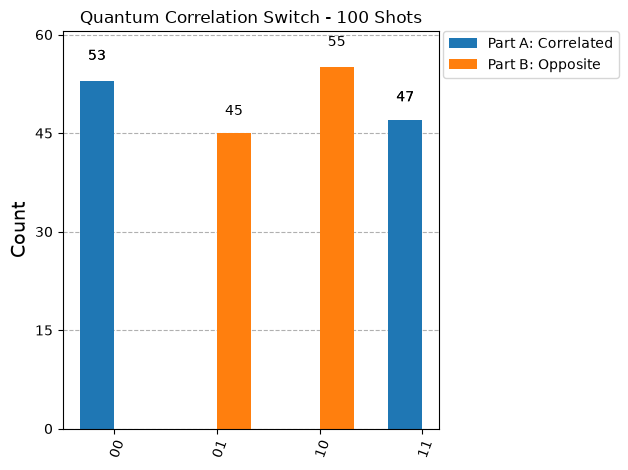

In [15]:
plot_histogram(
    [counts_a, counts_b],
    legend=["Part A: Correlated", "Part B: Opposite"],
    title="Quantum Correlation Switch - 100 Shots"
)

plt.show()

In [16]:
print("COMPARISON OF MEASUREMENT RESULTS")
print("-" * 40)

for label, counts in [
    ("Part A - Correlated", counts_a),
    ("Part B - Opposite", counts_b)
]:
    print(f"\n{label}")

    for outcome in ["00", "01", "10", "11"]:
        count = counts.get(outcome, 0)
        print(f"{outcome}: {count} shots ({count}%)")

COMPARISON OF MEASUREMENT RESULTS
----------------------------------------

Part A - Correlated
00: 53 shots (53%)
01: 0 shots (0%)
10: 0 shots (0%)
11: 47 shots (47%)

Part B - Opposite
00: 0 shots (0%)
01: 45 shots (45%)
10: 55 shots (55%)
11: 0 shots (0%)


## Comparison and Conclusion

In Part A, the Hadamard gate and CNOT gate create the Bell state:

\[
|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}
\]

The dominant outcomes are `00` and `11`, meaning that both qubits produce the same measurement result.

In Part B, an X gate is applied to the second qubit. This flips the second qubit and transforms the state into:

\[
|\Psi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt{2}}
\]

The dominant outcomes are now `01` and `10`, meaning that the qubits produce opposite measurement results.

The relationship changes because the X gate flips the second qubit without changing the equal probabilities of the two possible outcomes. In an ideal simulator, only the two expected outcomes appear for each circuit.

This experiment demonstrates that a small change to a quantum circuit can switch the measurement relationship between two entangled qubits from correlated to anti-correlated.